# Lab 1 — Introduction to Image Processing

Reads and resizes an image, marks a blue ROI, crops vertical halves and horizontal quarters, and draws a white line on a grayscale image.

Each operation is presented in two styles. Style 1 uses OpenCV built-in operations. Style 2 uses OpenCV only to read images and Matplotlib to display them; the processing logic is written manually.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

LAB_DIR = Path.cwd()

def image_path(name):
    # Works when the notebook is opened from its Lab directory or repository root.
    candidates = [LAB_DIR / name, LAB_DIR / "Lab Practicals" / name]
    return next((path for path in candidates if path.exists()), candidates[0])

def show_images(images, titles, cmap=None, figsize=(14, 4)):
    fig, axes = plt.subplots(1, len(images), figsize=figsize)
    axes = np.atleast_1d(axes)
    for axis, image, title in zip(axes, images, titles):
        axis.imshow(image, cmap=cmap)
        axis.set_title(title)
        axis.axis("off")
    plt.tight_layout()
    plt.show()


## Style 1 — OpenCV built-in operations

In [2]:
def prepare_image_cv(path, size=(200, 200)):
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    return cv2.resize(image, size, interpolation=cv2.INTER_AREA)

def roi_rectangle_cv(image):
    result = image.copy()
    # OpenCV stores colour images as BGR, so blue is (255, 0, 0).
    return cv2.rectangle(result, (80, 80), (160, 160), (255, 0, 0), 5)

def crop_halves_and_quarters_cv(image, output_dir="lab1_crops_cv"):
    output = Path(output_dir)
    output.mkdir(exist_ok=True)
    height, width = image.shape[:2]
    vertical = [image[:, :width // 2], image[:, width // 2:]]
    horizontal = [part[:, j * (width // 4):(j + 1) * (width // 4)]
                  for j in range(4)]
    for index, part in enumerate(vertical, 1):
        cv2.imwrite(str(output / f"vertical_{index}.png"), part)
    for index, part in enumerate(horizontal, 1):
        cv2.imwrite(str(output / f"horizontal_{index}.png"), part)
    return vertical, horizontal

def grayscale_line_cv(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return cv2.line(gray, (80, 80), (160, 80), 255, 5)


## Style 2 — DSA/manual implementation

In [3]:
def resize_nearest_manual(image, size=(200, 200)):
    target_width, target_height = size
    source_height, source_width = image.shape[:2]
    result = np.zeros((target_height, target_width, image.shape[2]), dtype=image.dtype)
    for row in range(target_height):
        source_row = min(int(row * source_height / target_height), source_height - 1)
        for col in range(target_width):
            source_col = min(int(col * source_width / target_width), source_width - 1)
            result[row, col] = image[source_row, source_col]
    return result

def roi_rectangle_manual(image):
    result = image.copy()
    # Draw a five-pixel border by writing each side explicitly.
    for thickness in range(5):
        top, bottom = 80 + thickness, 160 - thickness
        left, right = 80 + thickness, 160 - thickness
        result[top, left:right + 1] = (255, 0, 0)
        result[bottom, left:right + 1] = (255, 0, 0)
        result[top:bottom + 1, left] = (255, 0, 0)
        result[top:bottom + 1, right] = (255, 0, 0)
    return result

def grayscale_manual(image):
    result = np.zeros(image.shape[:2], dtype=np.uint8)
    for row in range(image.shape[0]):
        for col in range(image.shape[1]):
            blue, green, red = image[row, col]
            result[row, col] = np.clip(0.114 * blue + 0.587 * green + 0.299 * red, 0, 255)
    return result

def line_manual(gray_image):
    result = gray_image.copy()
    # Horizontal line with a five-pixel vertical thickness.
    result[78:83, 80:161] = 255
    return result

def crop_halves_and_quarters_manual(image):
    height, width = image.shape[:2]
    halves = [image[:, :width // 2], image[:, width // 2:]]
    quarters = [image[:, j * (width // 4):(j + 1) * (width // 4)] for j in range(4)]
    return halves, quarters


## Demonstration

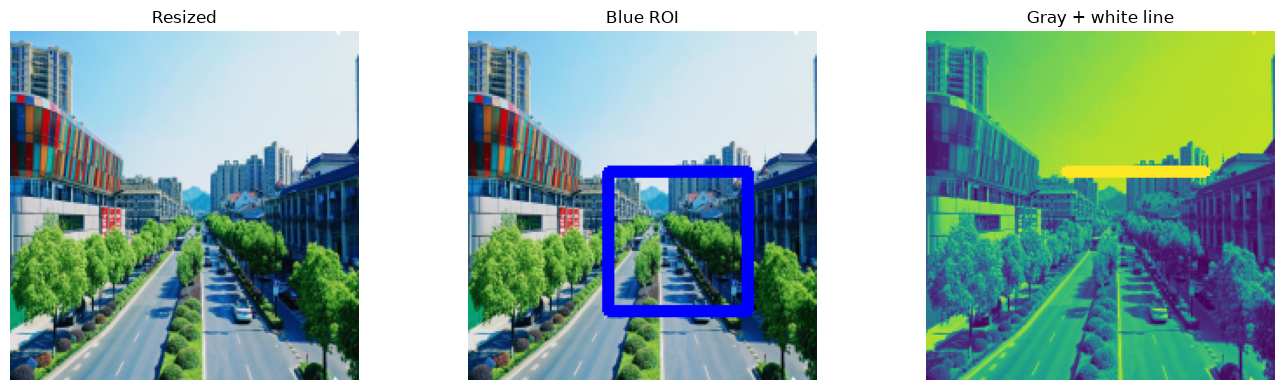

Manual vertical halves: [(200, 100, 3), (200, 100, 3)]
Manual horizontal quarters: [(200, 50, 3), (200, 50, 3), (200, 50, 3), (200, 50, 3)]


In [4]:
source = image_path("Lab1/Image/Natural_scene.jpg")
if not source.exists():
    source = image_path("Image/Natural_scene.jpg")
original = cv2.imread(str(source), cv2.IMREAD_COLOR)
if original is None:
    original = np.zeros((240, 240, 3), np.uint8)
cv_image = prepare_image_cv(source) if source.exists() and cv2.imread(str(source)) is not None else cv2.resize(original, (200, 200))
manual_image = resize_nearest_manual(original, (200, 200))
show_images([cv_image[:, :, ::-1], roi_rectangle_cv(cv_image)[:, :, ::-1],
            grayscale_line_cv(cv_image)], ["Resized", "Blue ROI", "Gray + white line"])
halves, quarters = crop_halves_and_quarters_manual(manual_image)
print("Manual vertical halves:", [part.shape for part in halves])
print("Manual horizontal quarters:", [part.shape for part in quarters])
